In [1]:
import re
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
from google.colab import files

uploaded = files.upload()
csv_name = list(uploaded.keys())[0]

try:
    df = pd.read_csv(csv_name)
except UnicodeDecodeError:
    df = pd.read_csv(csv_name, encoding="latin-1")

print("Loaded file:", csv_name)
print("Shape (rows, columns):", df.shape)
print("Columns:", list(df.columns))
df.head()

Saving Resume.csv to Resume.csv
Loaded file: Resume.csv
Shape (rows, columns): (2484, 4)
Columns: ['ID', 'Resume_str', 'Resume_html', 'Category']


,ID,Resume_str,Resume_html,Category
0,16852973,HR ADMINISTRATOR/MARKETING ASSOCIATE\...,"<div class=""fontsize fontface vmargins hmargin...",HR
1,22323967,"HR SPECIALIST, US HR OPERATIONS ...","<div class=""fontsize fontface vmargins hmargin...",HR
2,33176873,HR DIRECTOR Summary Over 2...,"<div class=""fontsize fontface vmargins hmargin...",HR
3,27018550,HR SPECIALIST Summary Dedica...,"<div class=""fontsize fontface vmargins hmargin...",HR
4,17812897,HR MANAGER Skill Highlights ...,"<div class=""fontsize fontface vmargins hmargin...",HR


In [3]:
# Keep only the columns we need
df = df[["Resume_str", "Category"]].copy()

print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows with missing text or label
df = df.dropna(subset=["Resume_str", "Category"])

# Remove exact duplicate resumes
before = len(df)
df = df.drop_duplicates(subset=["Resume_str"])
print(f"\nDuplicates removed: {before - len(df)}")

# Tidy category names
df["Category"] = df["Category"].astype(str).str.strip()
print("Rows remaining:", len(df))

Missing values before cleaning:
Resume_str    0
Category      0
dtype: int64

Duplicates removed: 2
Rows remaining: 2482


In [4]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"<.*?>", " ", text)                 # HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)      # URLs
    text = re.sub(r"\S+@\S+", " ", text)               # emails
    text = re.sub(r"[^a-zA-Z\s]", " ", text)           # keep letters only
    text = re.sub(r"\s+", " ", text).strip().lower()   # extra spaces + lowercase
    return text

df["Clean_Resume"] = df["Resume_str"].apply(clean_text)

# Drop resumes that became empty after cleaning
df = df[df["Clean_Resume"].str.len() > 0].reset_index(drop=True)

print("Rows after cleaning:", len(df))
df[["Category", "Clean_Resume"]].head()


Rows after cleaning: 2481


,Category,Clean_Resume
0,HR,hr administrator marketing associate hr admini...
1,HR,hr specialist us hr operations summary versati...
2,HR,hr director summary over years experience in r...
3,HR,hr specialist summary dedicated driven and dyn...
4,HR,hr manager skill highlights hr skills hr depar...


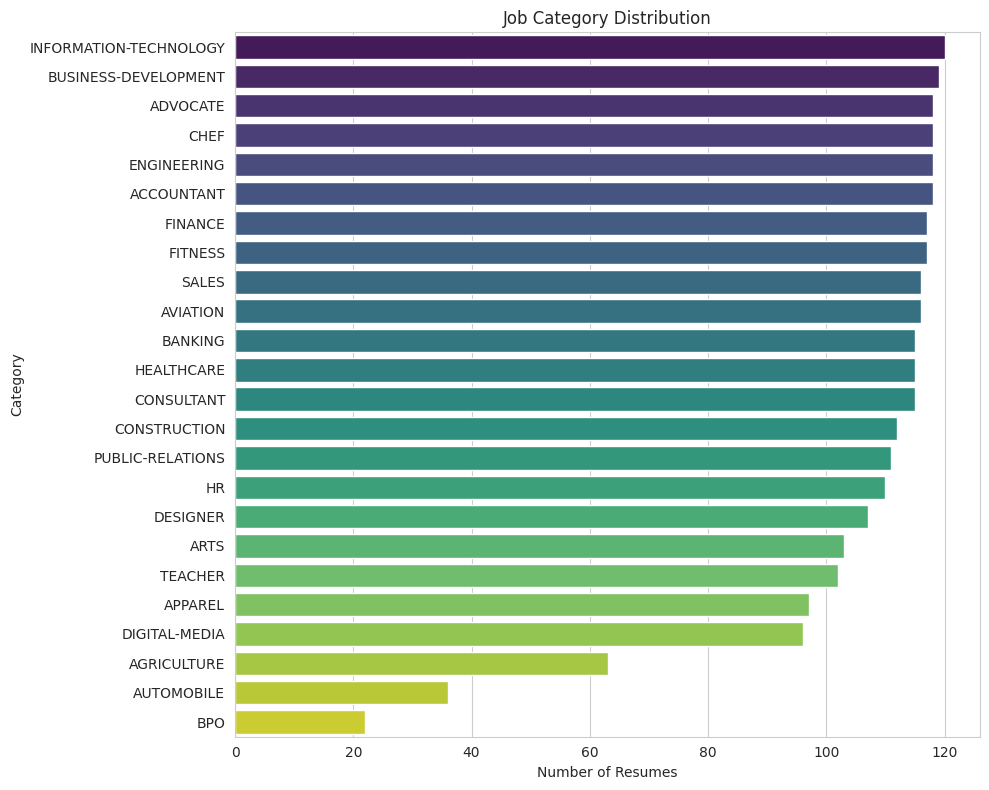

Category
INFORMATION-TECHNOLOGY    120
BUSINESS-DEVELOPMENT      119
ADVOCATE                  118
CHEF                      118
ENGINEERING               118
ACCOUNTANT                118
FINANCE                   117
FITNESS                   117
SALES                     116
AVIATION                  116
BANKING                   115
HEALTHCARE                115
CONSULTANT                115
CONSTRUCTION              112
PUBLIC-RELATIONS          111
HR                        110
DESIGNER                  107
ARTS                      103
TEACHER                   102
APPAREL                    97
DIGITAL-MEDIA              96
AGRICULTURE                63
AUTOMOBILE                 36
BPO                        22
Name: count, dtype: int64


In [5]:
plt.figure(figsize=(10, 8))
order = df["Category"].value_counts().index
sns.countplot(data=df, y="Category", order=order, palette="viridis")
plt.title("Job Category Distribution")
plt.xlabel("Number of Resumes")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

print(df["Category"].value_counts())

In [6]:
X = df["Clean_Resume"]
y = df["Category"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

Training samples: 1984
Testing samples : 497


In [7]:
def make_tfidf():
    return TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b",
        ngram_range=(1, 2),
        max_features=20000,
        sublinear_tf=True
    )

models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", make_tfidf()),
        ("clf", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", make_tfidf()),
        ("clf", LogisticRegression(max_iter=1000, random_state=42))
    ]),
}
print("Pipelines created:", list(models.keys()))

Pipelines created: ['Multinomial Naive Bayes', 'Logistic Regression']


In [16]:
results = []
predictions = {}

for name, pipe in models.items():
    print(f"Training {name} ...")
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    })

results_df = pd.DataFrame(results).set_index("Model")
results_df.round(4)

Training Multinomial Naive Bayes ...
Training Logistic Regression ...
Training Logistic Regression (tuned) ...


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,
Multinomial Naive Bayes,0.5352,0.5520,0.5352,0.4872
Logistic Regression,0.6378,0.6661,0.6378,0.6093
Logistic Regression (tuned),0.6901,0.7053,0.6901,0.6814


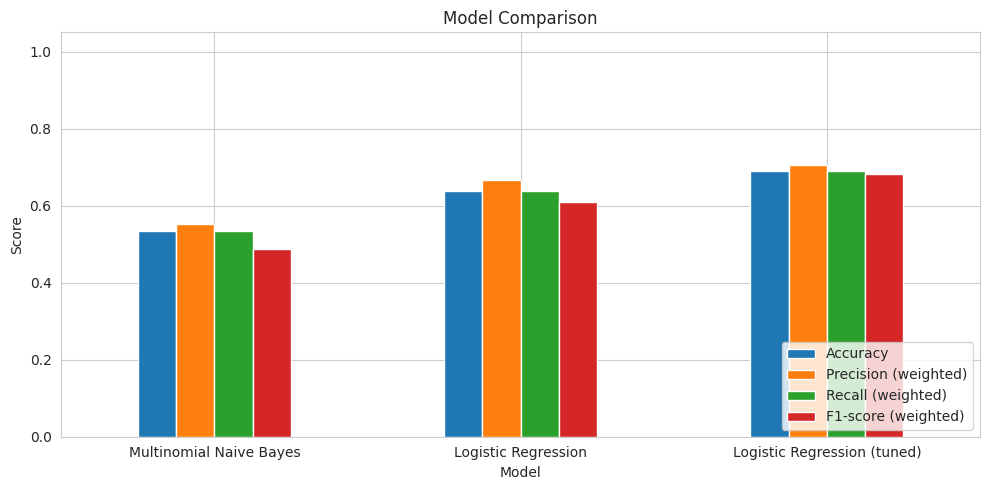

Best model (by weighted F1-score): Logistic Regression (tuned)


In [18]:
results_df.round(4).plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
plt.title("Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

best_name = results_df["F1-score (weighted)"].idxmax()
best_model = models[best_name]
print("Best model (by weighted F1-score):", best_name)

In [19]:
for name, y_pred in predictions.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, y_pred, zero_division=0))

Multinomial Naive Bayes
                        precision    recall  f1-score   support

            ACCOUNTANT       0.43      0.88      0.58        24
              ADVOCATE       0.26      0.33      0.29        24
           AGRICULTURE       1.00      0.08      0.14        13
               APPAREL       0.00      0.00      0.00        19
                  ARTS       1.00      0.10      0.17        21
            AUTOMOBILE       0.00      0.00      0.00         7
              AVIATION       0.83      0.65      0.73        23
               BANKING       0.80      0.52      0.63        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.37      0.88      0.52        24
                  CHEF       0.78      0.75      0.77        24
          CONSTRUCTION       0.64      0.64      0.64        22
            CONSULTANT       0.00      0.00      0.00        23
              DESIGNER       0.76      0.62      0.68        21
         DIGITA

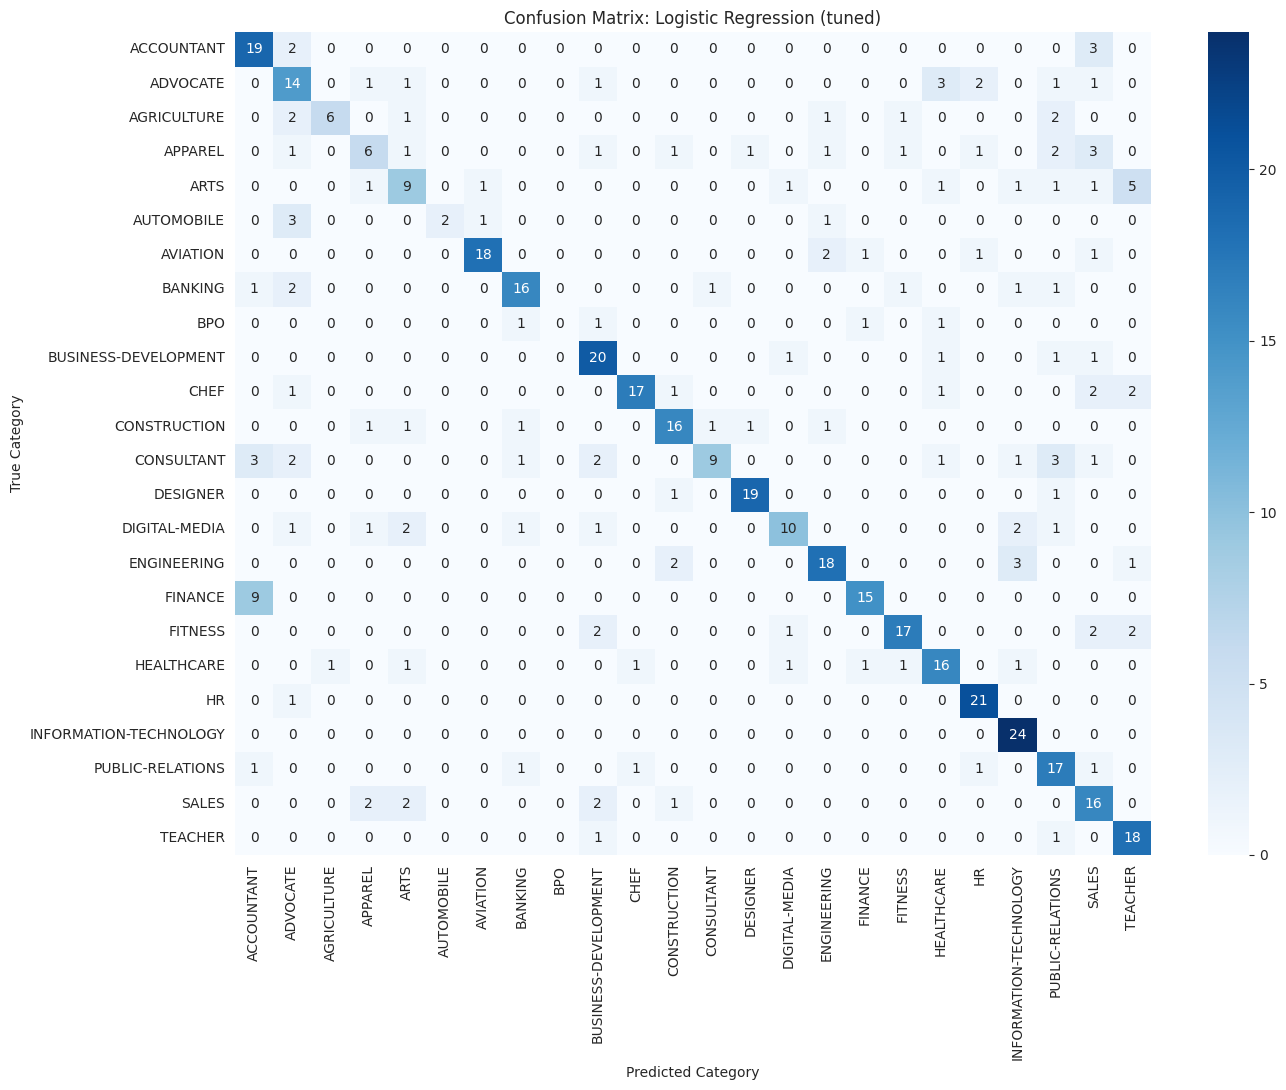

In [20]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, predictions[best_name], labels=labels)

plt.figure(figsize=(14, 11))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels, cbar=True)
plt.title(f"Confusion Matrix: {best_name}")
plt.xlabel("Predicted Category")
plt.ylabel("True Category")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:
from sklearn.model_selection import GridSearchCV

base_pipe = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])

param_grid = {
    "clf__C": [1, 10, 50],
    "clf__class_weight": [None, "balanced"],
}

grid = GridSearchCV(base_pipe, param_grid, cv=3, scoring="f1_macro", n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best cross-validated macro F1:", round(grid.best_score_, 4))

# Evaluate on the test set and add it to the comparison
tuned_name = "Logistic Regression (tuned)"
tuned_model = grid.best_estimator_
y_pred = tuned_model.predict(X_test)

models[tuned_name] = tuned_model
predictions[tuned_name] = y_pred
results_df.loc[tuned_name] = [
    accuracy_score(y_test, y_pred),
    precision_score(y_test, y_pred, average="weighted", zero_division=0),
    recall_score(y_test, y_pred, average="weighted", zero_division=0),
    f1_score(y_test, y_pred, average="weighted", zero_division=0),
]
results_df.round(4)

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best settings: {'clf__C': 50, 'clf__class_weight': 'balanced'}
Best cross-validated macro F1: 0.6052


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,
Multinomial Naive Bayes,0.5352,0.5520,0.5352,0.4872
Logistic Regression,0.6378,0.6661,0.6378,0.6093
Logistic Regression (tuned),0.6901,0.7053,0.6901,0.6814


In [14]:
def add_title_boost(text, n_words=5, repeat=3):
    title = " ".join(text.split()[:n_words])
    return (title + " ") * repeat + text

X_train_b = X_train.apply(add_title_boost)
X_test_b  = X_test.apply(add_title_boost)

boost_model = Pipeline([
    ("tfidf", make_tfidf()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced"))
])
boost_model.fit(X_train_b, y_train)
y_pred_b = boost_model.predict(X_test_b)

print("Accuracy:", round(accuracy_score(y_test, y_pred_b), 4))
print("Weighted F1:", round(f1_score(y_test, y_pred_b, average="weighted"), 4))
print(classification_report(y_test, y_pred_b, zero_division=0))

Accuracy: 0.7002
Weighted F1: 0.6865
                        precision    recall  f1-score   support

            ACCOUNTANT       0.60      0.88      0.71        24
              ADVOCATE       0.58      0.62      0.60        24
           AGRICULTURE       0.78      0.54      0.64        13
               APPAREL       0.80      0.21      0.33        19
                  ARTS       0.67      0.38      0.48        21
            AUTOMOBILE       0.67      0.57      0.62         7
              AVIATION       0.90      0.78      0.84        23
               BANKING       0.89      0.70      0.78        23
                   BPO       0.00      0.00      0.00         4
  BUSINESS-DEVELOPMENT       0.58      0.88      0.70        24
                  CHEF       0.86      0.75      0.80        24
          CONSTRUCTION       0.82      0.82      0.82        22
            CONSULTANT       0.78      0.30      0.44        23
              DESIGNER       0.83      0.95      0.89        21
  

In [21]:
files.download("skillmatch_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>